**This is the 1 Session Jupyter Notebook (25/11/26)**

In [1]:
# %pip install qiskit qiskit-aer matplotlib pylatexenc sympy

from qiskit import QuantumRegister, QuantumCircuit
from qiskit_aer import Aer
from qiskit import quantum_info as qi
from qiskit.visualization import plot_bloch_multivector
import numpy as np

In [ ]:
# We import the linear algebra module from numpy to compute the eigenvalues and eigenvectors of a matrix
from numpy import linalg as LA

In [4]:
# This define a row column vector
v = np.array([1., 0.])
print(v)

[1. 0.]


In [5]:
# This defines a column vector
v = np.array([[1.], [0.]])
print(v)

[[1.]
 [0.]]


In [ ]:
# This defines a complex number
c = complex(0.5,  0.4)
print(c)

# W
print(c.real)
print(c.imag)

(0.5+0.4j)
0.5
0.4


In [10]:
vket = np.array([[1.], [0.]])
vbra = vket.conj().T # Conjugates first and then transposes the vector
print(vbra)
vbra = vket.T.conj() # Transposes first and then conjugates the vector
print(vbra)

[[1. 0.]]
[[1. 0.]]


In [ ]:
# Now, we can use the Qiskit library to create a statevector and visualize it in LaTeX format.
from qiskit import quantum_info as qi
from qiskit.visualization import array_to_latex

**Why doesn't `array_to_latex(sv)` show a column vector?**

Even though we pass a column vector `np.array([[1.], [0.]])` (shape `(2, 1)`), `qi.Statevector` **flattens it into a 1D array** of shape `(2,)` (check with `sv.data.shape` or `print(sv)`, which shows `dims=(2,)`). A 1D array has no row/column orientation, so `array_to_latex` renders it as a single row. The state is still correct; only the display changes.

To display it as a proper column vector, or in Dirac notation:

```python
array_to_latex(sv.data.reshape(-1, 1))   # shape (2, 1) -> column vector
sv.draw('latex')                         # Dirac notation: |0⟩
```

In [16]:
# Create a statevector, which is a column vector representing the qubit.
sv = qi.Statevector(np.array([[1.], [0.]]))

array_to_latex(sv)


<IPython.core.display.Latex object>

In [ ]:
# Create an operator, which is a square matrix representing a quantum operation.
op = qi.Operator([[1., 0.], [0., -1.]])
array_to_latex(op)

<IPython.core.display.Latex object>

In [ ]:
# Check if the operator is unitary, which means that it preserves the norm of the statevector.
op1.is_unitary()

True

In [36]:
op2 = qi.random_unitary(2, seed=23112026)
array_to_latex(op2, precision = 3)


<IPython.core.display.Latex object>

In [ ]:
# This code computes the product of the operator and its adjoint (conjugate transpose) 
# and visualizes it in LaTeX format. 

# Concretely, this should return the identity matrix because a unitary operator multiplied by 
# its adjoint is equal to the identity matrix.

array_to_latex(op2.compose(op2.adjoint()))

<IPython.core.display.Latex object>

In [ ]:
# This code creates the Pauli matrices X, Y, and Z, which are fundamental 
# quantum gates used in quantum computing.

x = qi.Operator(qi.Pauli('X'))
array_to_latex(x)

<IPython.core.display.Latex object>

In [46]:
y = qi.Operator(qi.Pauli('Y'))
array_to_latex(y)

<IPython.core.display.Latex object>

In [47]:
z = qi.Operator(qi.Pauli('Z'))
array_to_latex(z)

<IPython.core.display.Latex object>

In [ ]:
# Tensor product of X and Y
array_to_latex(x.tensor(y))

<IPython.core.display.Latex object>

In [53]:
sv0 = qi.Statevector(np.array([[1.], [0.]]))

# This code evolves the statevector sv0 by applying the operator x to it, 
# resulting in a new statevector sv1.

sv1 = sv0.evolve(x)

# Operator x is the Pauli-X gate, which flips the state of a qubit,
# which means that it transforms the |0⟩ state to the |1⟩ state and vice versa.
array_to_latex(sv1)

<IPython.core.display.Latex object>

In [58]:
# A QuantumRegister is a collection of qubits that can be used to build quantum circuits.
from qiskit import QuantumRegister

# Create a quantum register with 1 qubit named 'Qreg'.
qr = QuantumRegister(1, 'Qreg')

# A QuantumCircuit is a sequence of quantum gates and measurements that can be applied 
# to a quantum register.
from qiskit import QuantumCircuit
# Create a quantum circuit with the quantum register qr.
qc = QuantumCircuit(qr)
# All quantum circuits start in the |0⟩ state, which is represented by the statevector sv0.
# Every quantum circuit starts in the |0⟩ state.
qc.draw(initial_state=True)

Qreg: |0>

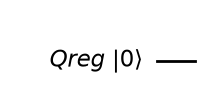

In [ ]:
# This code draws the quantum circuit using the matplotlib backend 
# and shows the initial state of the qubit.

# mpl means that the circuit will be drawn using the matplotlib library.
qc.draw('mpl', initial_state=True)